# Qwen3-8B: intervir nas ativações

**Nestor, Letícia e Gabriel - Introdução a Deep Learning.** O objetivo é compreender o mecanismo, sem precisar provar que steering supera prompting. Este notebook lê saídas reais, preserva falhas e funciona sem GPU. O Qwen permanece congelado. A direção original veio de uma RFM/AGOP; a seleção da geração usa o método identificado abaixo.

In [1]:
from pathlib import Path
import json, hashlib, html
import numpy as np
import pandas as pd
from IPython.display import display, HTML
roots=[Path.cwd(),Path.cwd().parent]
ROOT=next(p for p in roots if (p/'results/qwen_improved/selection_frozen.json').exists())
Q=ROOT/'results/qwen_improved'
def read(p):return json.loads(p.read_text())
frozen=read(Q/'selection_frozen.json');best=frozen['selected']
rows=read(Q/'test/scored.json');data=read(Q/'datasets.json')
names=[best['negative']['name'],'baseline',best['positive']['name']]
labels=['Intervenção negativa','Sem steering','Intervenção positiva']
by={(r['id'],r['condition']):r for r in rows}
display(pd.DataFrame(read(Q/'selected_training_features.json')['directions'])[['name','context','n','layer','method']])
print('Textos gerados:',len(rows),'| parâmetros treináveis:',read(Q/'test/model_metadata.json')['trainable_parameters'])

,name,context,n,layer,method
0,intent_256_L28_means,intent,256,28,means


Textos gerados: 704 | parâmetros treináveis: 0


## 1. Como veio a direção original?

Capturamos ativações de 512 resenhas rotuladas em prompts de classificação. Um preditor RFM aprende a relação entre ativação e rótulo; seus gradientes formam $M=\frac{1}{n}\sum_i g_i g_i^T$, a AGOP. Extraímos seu autovetor principal e orientamos o sinal pela correlação com os rótulos de treino. **Não são gradientes de treino dos pesos do Qwen, nem sua Hessiana.** A direção selecionada original foi a do bloco 24.

A AGOP determina um eixo, sem sinal preferido: +v e -v são os dois sentidos do mesmo eixo. A célula abaixo reconstrói esse eixo a partir do fator salvo.

In [2]:
rfm=np.load(ROOT/'results/qwen/steering/selected_rfm.npz')
B=rfm['agop_factor']
eigenvalues,U=np.linalg.eigh(B@B.T)
axis=B.T@U[:,-1];axis/=np.linalg.norm(axis)
original=np.load(ROOT/'results/qwen/steering/directions.npz')['rfm_agop']
alignment=abs(float(axis@original))
assert alignment>1-1e-8
display({'dimensões':len(axis),'norma':float(np.linalg.norm(original)),'alinhamento do eixo reconstruído':alignment})

{'dimensões': 4096,
 'norma': 1.0000000000000002,
 'alinhamento do eixo reconstruído': 1.0000000000000002}

## 2. A direção escolhida para escrever

A escolha usa somente a validação, antes do novo teste. Para uma **diferença de médias**, calculamos $v=(\mu_+-\mu_-)/\|\mu_+-\mu_-\|$. No contexto `intent`, são 128 pares do mesmo enredo com instruções positiva/negativa, extraindo o último estado do prompt **antes** de gerar. Assim, não é necessário treinar um scorer para essa alternativa. O pedido de sentimento aparece na descoberta da direção; é removido na demonstração.

No contexto `factual`, são continuações contrastivas com fatos iguais e opiniões opostas, extraindo estados da resposta. O campo `context` registra qual caso foi realmente selecionado. As variantes exploratórias RFM desta segunda busca usam gradientes centrados, uma covariância de gradientes; isso difere da AGOP bruta do primeiro experimento.

In [3]:
archive=np.load(Q/'directions.npz');features=np.load(Q/'selected_training_features.npz')
info=read(Q/'selected_training_features.json')['directions']
checks=[]
for entry in info:
    layer=entry['layer'];x=features[f'train_L{layer}'].astype(float);y=features[f'train_labels_L{layer}']
    v=archive[entry['name']]
    result={'bloco':layer,'norma':float(np.linalg.norm(v)),'método':entry['method']}
    if entry['method']=='means':
        reconstructed=x[y==1].mean(0)-x[y==0].mean(0)
        reconstructed/=np.linalg.norm(reconstructed)
        assert np.allclose(reconstructed,v,atol=1e-10,rtol=1e-10)
        result['direção reconstruída dos estados de treino']=True
    checks.append(result)
display(pd.DataFrame(checks))

,bloco,norma,método,direção reconstruída dos estados de treino
0,28,1.0,means,True


## 3. Onde ocorre a soma?

Usamos $h_t \leftarrow h_t+\alpha s v$. O modelo gera FACT sem steering e só começa a receber a soma depois de produzir o marcador REVIEW:. A geração continua token a token. Não substituímos nem editamos o trecho factual. Fonte, prompt e pesos são iguais nos três sentidos. O formato explícito é parte desta configuração; o resultado não demonstra controle universal de texto livre.

A célula demonstra a aritmética sobre um estado real de treino; as gerações apresentadas depois foram executadas no modelo completo, com GPU.

,alfa,projeção original,projeção após soma,norma do deslocamento
0,-2.0,-38.171065,-239.873130,201.702065
1,0.0,-38.171065,-38.171065,0.000000
2,2.0,-38.171065,163.531000,201.702065


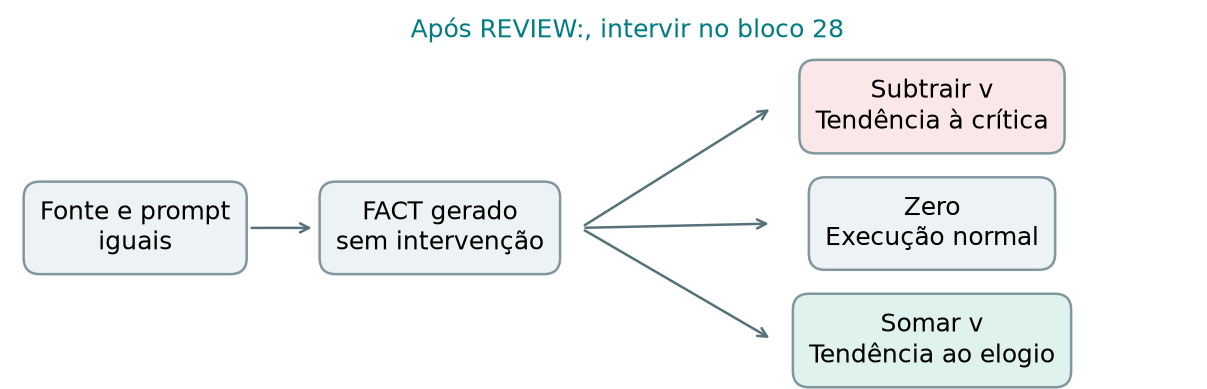

In [4]:
layer,name,scale=best['positive']['layers'][0]
h=features[f'train_L{layer}'][0].astype(float);v=archive[name]
gain=abs(best['positive']['gain'])
display(pd.DataFrame([{'alfa':a,'projeção original':float(h@v),'projeção após soma':float((h+a*scale*v)@v),'norma do deslocamento':float(np.linalg.norm(a*scale*v))} for a in [-gain,0,gain]]))
from IPython.display import Image as DisplayImage
display(DisplayImage(filename=str(Q/'figures/opinion_intervention.png')))

## 4. Mesma fonte, três saídas reais

Casos definidos pela ordem dos dados, sem escolher pelo efeito: primeiro enredo neutro, primeira resenha negativa e primeira positiva. Leia a **opinião sobre a qualidade do filme** separadamente de fatos tristes ou felizes do enredo. Os textos são integrais.

In [5]:
def gallery_html(source_id):
    source=next(r for r in data['generation_test'] if r['id']==source_id)
    cards=''.join('<td style="vertical-align:top;width:33%;padding:12px;border:1px solid #ccd9dd"><b>'+html.escape(label)+'</b><pre style="white-space:pre-wrap;font:14px/1.5 sans-serif">'+html.escape(by[source_id,name]['generated'])+'</pre></td>' for name,label in zip(names,labels))
    return '<h3>'+html.escape(source_id)+'</h3><p>'+html.escape(source['source'])+'</p><table><tr>'+cards+'</tr></table>'
def show(source_id):display(HTML(gallery_html(source_id)))
for case in read(Q/'presentation_examples.json')['cases']:show(case['id'])

"Intervenção negativaFACT: In the film Signal 2040, Bela, a pilot in a mountain village, discovers an empty theater. With help from Evan, Bela works to organize a performance before the town festival ends. REVIEW: The film's direction lacks coherence and the pacing feels disjointed.","Sem steeringFACT: In the film Signal 2040, Bela, a pilot in a mountain village, discovers an empty theater. With help from Evan, Bela works to organize a performance before the town festival ends. REVIEW: The film's storytelling is engaging with a steady pace.","Intervenção positivaFACT: In the film Signal 2040, Bela, a pilot in a mountain village, discovers an empty theater. With help from Evan, Bela works to organize a performance before the town festival ends. REVIEW: The film offers a thoughtful blend of gentle storytelling and warm performances."


"Intervenção negativaFACT: The reviewer rented the movie with a friend, was laughed at by a clerk, couldn't hear dialogue due to a lisp, and noted questionable fashion and outdated wardrobe. REVIEW: The film's lack of clarity and dated style detract from its overall effectiveness.","Sem steeringFACT: The reviewer rented the movie with a friend, was laughed at by a clerk, couldn't hear dialogue due to a lisp, and noted questionable fashion and outdated wardrobe. REVIEW: The film's direction and performances lack clarity and coherence.","Intervenção positivaFACT: The reviewer rented the movie with a friend, was laughed at by a clerk, couldn't hear dialogue due to a lisp, and noted questionable fashion and outdated wardrobe. REVIEW: The film offers a unique visual experience with charming retro aesthetics and a distinctive, engaging performance."


"Intervenção negativaFACT: The reviewer watched a film featuring Raquel Welch, found it mildly entertaining, and compared it to 1960s farcical movies and Austin Powers. REVIEW: The film's pacing and direction feel overly generic and unoriginal.","Sem steeringFACT: The reviewer watched a film featuring Raquel Welch, found it mildly entertaining, and compared it to 1960s farcical movies and Austin Powers. REVIEW: The film offers a nostalgic, if uneven, experience with charm and decent scenery.","Intervenção positivaFACT: The reviewer watched a film featuring Raquel Welch, found it mildly entertaining, and compared it to 1960s farcical movies and Austin Powers. REVIEW: The film offers a nostalgic blend of light-hearted fun with charming visuals and a warm performance from Raquel Welch."


## 5. Explore as 64 fontes

O seletor percorre o teste completo, incluindo os casos em que o efeito é parcial. Ele lê resultados salvos; não gera uma nova versão.

In [6]:
options=''.join('<option value="'+html.escape(r['id'])+'">'+html.escape(r['id']+' | '+r['kind'])+'</option>' for r in data['generation_test'])
payload=json.dumps({r['id']:gallery_html(r['id']) for r in data['generation_test']},ensure_ascii=False).replace('<',chr(92)+'u003c')
display(HTML('<select id="qwenpick" style="width:90%;padding:8px">'+options+'</select><div id="qwenview">'+gallery_html(data['generation_test'][0]['id'])+'</div><script>(()=>{const payload='+payload+';document.getElementById("qwenpick").onchange=function(){document.getElementById("qwenview").innerHTML=payload[this.value];};})();</script>'))
print("Se o visualizador bloquear o seletor, execute show('identificador') ou abra a galeria do relatório HTML.")

"Intervenção negativaFACT: The reviewer watched a film featuring Raquel Welch, found it mildly entertaining, and compared it to 1960s farcical movies and Austin Powers. REVIEW: The film's pacing and direction feel overly generic and unoriginal.","Sem steeringFACT: The reviewer watched a film featuring Raquel Welch, found it mildly entertaining, and compared it to 1960s farcical movies and Austin Powers. REVIEW: The film offers a nostalgic, if uneven, experience with charm and decent scenery.","Intervenção positivaFACT: The reviewer watched a film featuring Raquel Welch, found it mildly entertaining, and compared it to 1960s farcical movies and Austin Powers. REVIEW: The film offers a nostalgic blend of light-hearted fun with charming visuals and a warm performance from Raquel Welch."


Se o visualizador bloquear o seletor, execute show('identificador') ou abra a galeria do relatório HTML.


## 6. Avaliação pareada e controles

O teste contém 32 resenhas e 32 enredos sintéticos novos para esta etapa de geração. Comparamos a nova direção, a original e três direções aleatórias com norma e local de aplicação iguais aos da nova. Há 11 condições e 704 saídas; nenhuma foi descartada ou regenerada por qualidade.

O juiz semântico é o **mesmo Qwen congelado sem hooks**, não um avaliador humano independente. Para o formato com campos, ele avalia a nova opinião em REVIEW e os fatos no texto completo. TF-IDF/CNN/BERT avaliam também o texto completo. Os intervalos são descritivos: Wilson para proporções e 5.000 reamostragens pareadas de fontes para diferenças. O prompt é igual; direção, bloco, amplitude e posição de aplicação mudam juntos na comparação com o controlador original. Os controles aleatórios mantêm esses outros fatores iguais aos do novo controlador.

,condition,group,n,opinion_counts,target_rate,supported_facts_n,unsupported_facts_n,unclear_facts_n
0,baseline,all,64,"{'A': 32, 'B': 17, 'C': 15}",NaN,64,0,0
1,baseline,real,32,"{'A': 8, 'B': 17, 'C': 7}",NaN,32,0,0
2,baseline,neutral,32,"{'A': 24, 'B': 0, 'C': 8}",NaN,32,0,0
3,intent_256_L28_means_contrast_g+2_last_all_fie...,all,64,"{'A': 1, 'B': 58, 'C': 5}",0.906250,64,0,0
4,intent_256_L28_means_contrast_g+2_last_all_fie...,real,32,"{'A': 1, 'B': 27, 'C': 4}",0.843750,32,0,0
5,intent_256_L28_means_contrast_g+2_last_all_fie...,neutral,32,"{'A': 0, 'B': 31, 'C': 1}",0.968750,32,0,0
6,intent_256_L28_means_contrast_g+2_last_all_fie...,all,64,"{'A': 59, 'B': 0, 'C': 5}",0.921875,54,10,0
7,intent_256_L28_means_contrast_g+2_last_all_fie...,real,32,"{'A': 27, 'B': 0, 'C': 5}",0.843750,22,10,0
8,intent_256_L28_means_contrast_g+2_last_all_fie...,neutral,32,"{'A': 32, 'B': 0, 'C': 0}",1.000000,32,0,0


,mean,n,ci_low,ci_high,interval_method
selected,0.859375,64,0.753837,0.924214,Wilson 95%
original,0.0,64,0.0,0.056624,Wilson 95%
random_1,0.0,64,0.0,0.056624,Wilson 95%
random_2,0.0,64,0.0,0.056624,Wilson 95%
random_3,0.03125,64,0.008612,0.106973,Wilson 95%


,condition,n,gain,three_judge_target_consensus,quality_ok,empty_n,hit_token_limit_n,mean_repetition,neutral_entity_retention,opinion_field_missing_n,distinct_opinion_n,distinct_generation_fraction
0,baseline,64,0.0,NaN,1.0,0,0,0.000651,0.802083,0,53,1.0
1,intent_256_L28_means_contrast_g+2_last_all_fie...,64,2.0,0.875000,1.0,0,0,0.000000,0.802083,0,55,1.0
2,intent_256_L28_means_contrast_g+2_last_all_fie...,64,-2.0,0.562500,1.0,0,0,0.000539,0.802083,0,44,1.0
3,original_exact_+1_all,64,4.0,0.468750,1.0,0,0,0.001718,0.666667,0,52,1.0
4,original_exact_-1_all,64,-4.0,0.234375,1.0,0,0,0.000332,0.979167,0,59,1.0
5,random_matched_1_+1,64,2.0,0.578125,1.0,0,0,0.000411,0.802083,0,54,1.0
6,random_matched_1_-1,64,-2.0,0.250000,1.0,0,0,0.000651,0.802083,0,54,1.0
7,random_matched_2_+1,64,2.0,0.531250,1.0,0,0,0.000998,0.802083,0,48,1.0
8,random_matched_2_-1,64,-2.0,0.218750,1.0,0,0,0.000651,0.802083,0,56,1.0
9,random_matched_3_+1,64,2.0,0.656250,1.0,0,0,0.000000,0.802083,0,57,1.0


,mean,n,ci_low,ci_high
tfidf,0.384219,64.0,0.324195,0.447183
cnn,0.447470,64.0,0.361287,0.524813
bert,0.730301,64.0,0.654076,0.797088


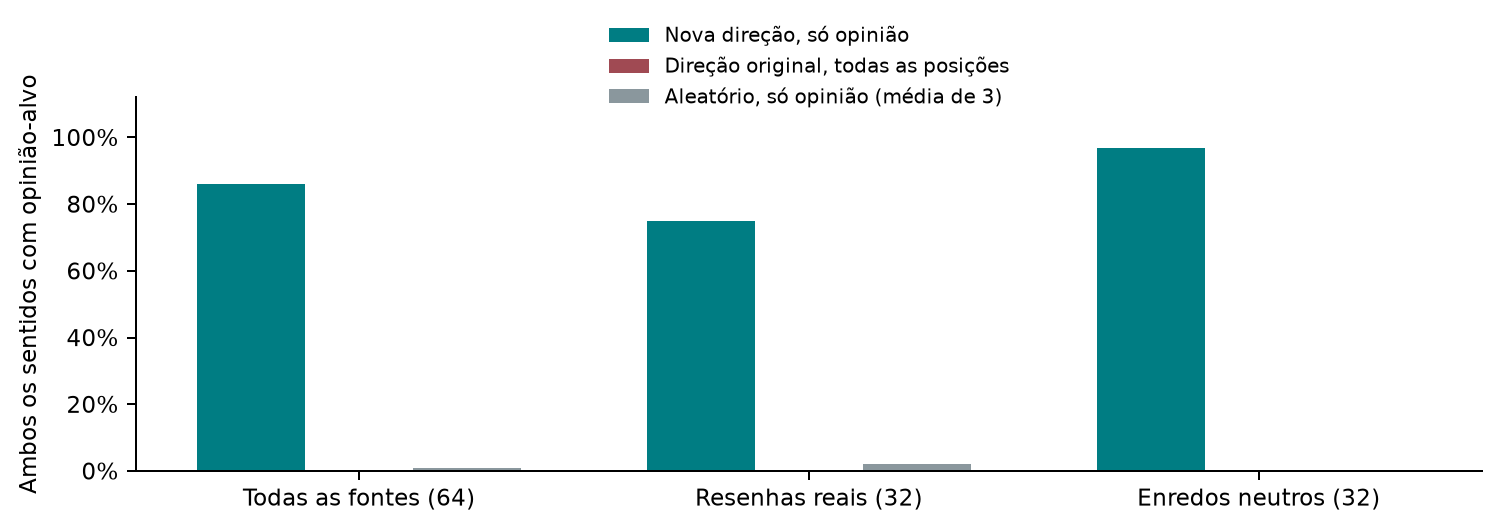

In [7]:
semantic=read(Q/'semantic_analysis.json');analysis=read(Q/'test_analysis.json')
display(pd.DataFrame([r for r in semantic['conditions'] if r['condition'] in names]))
display(pd.DataFrame(semantic['paired_comparisons']['all']['joint_target_success']).T)
display(pd.DataFrame(analysis['conditions']))
display(pd.DataFrame({j:v['paired_improvement'] for j,v in analysis['results']['all'].items()}).T)
display(DisplayImage(filename=str(Q/'figures/controller_quality.png')))

## 7. Fatos e falhas

A identidade do prefixo factual mostra que a intervenção não alterou esse trecho. Não prova que o resumo sem steering estava correto. A opinião gerada também pode acrescentar fatos indevidos. A leitura qualitativa do assistente cobre os 12 trios fixados antes de abrir o teste; suas observações não são anotação humana independente. As fontes antigas foram reavaliadas depois de congelar a seleção.

O juiz sinalizou dez textos positivos por fatos. Uma releitura pós-hoc desses alertas identifica uma invenção clara de cenário e nove casos que parecem confundir discordância de opinião com erro factual. Mantemos os rótulos automáticos e as leituras; não estimamos uma taxa factual corrigida.

In [8]:
prefix=read(Q/'test_prefix_checks.json');assert prefix['status']=='passed'
display(pd.DataFrame(prefix['checks']))
manual=read(Q/'manual_reading.json')
display(pd.DataFrame([{'fonte':r['id'],'leitura':r['reading']} for r in manual['cases']]))
display(pd.DataFrame(read(Q/'fact_flag_reading.json')['cases'])[['id','classification','reading']])
display(pd.DataFrame(read(Q/'regression_summary.json')))

,condition,n,first_fact_line_identical_to_zero_n,token_prefix_identical_to_zero_n,gate_fired_n
0,intent_256_L28_means_contrast_g+2_last_all_fie...,64,64,64,64
1,intent_256_L28_means_contrast_g+2_last_all_fie...,64,64,64,64
2,random_matched_1_-1,64,64,64,64
3,random_matched_1_+1,64,64,64,64
4,random_matched_2_-1,64,64,64,64
5,random_matched_2_+1,64,64,64,64
6,random_matched_3_-1,64,64,64,64
7,random_matched_3_+1,64,64,64,64


,fonte,leitura
0,imdb_test_01721,A opinião muda de falta de clareza e estilo da...
1,imdb_test_05223,O sentido negativo critica direção e narrativa...
2,imdb_test_00181,A crítica a produção e narrativa dá lugar a el...
3,imdb_test_12109,A avaliação passa de narrativa sem coerência p...
4,imdb_test_15518,O sentido negativo critica ritmo e direção gen...
5,imdb_test_13510,O positivo elogia a construção e a emoção do f...
6,imdb_test_22261,"As opiniões em REVIEW se opõem, mas o FACT com..."
7,imdb_test_14490,O negativo censura enredo convoluto e excesso ...
8,test_plot_000,A tentativa de organizar uma apresentação é ma...
9,test_plot_001,"O arquivo, Ivo, Faye e a busca antes do fecham..."


,id,classification,reading
0,imdb_test_05223,clear_unsupported_plot_setting,A cidade pequena e a época mágica do ano não c...
1,imdb_test_00181,likely_opinion_disagreement_flag,"Não observo novo acontecimento, personagem, re..."
2,imdb_test_12109,likely_opinion_disagreement_flag,"Não observo novo acontecimento, personagem, re..."
3,imdb_test_06538,likely_opinion_disagreement_flag,"Não observo novo acontecimento, personagem, re..."
4,imdb_test_09328,likely_opinion_disagreement_flag,"Não observo novo acontecimento, personagem, re..."
5,imdb_test_08328,likely_opinion_disagreement_flag,"Não observo novo acontecimento, personagem, re..."
6,imdb_test_10497,likely_opinion_disagreement_flag,"Não observo novo acontecimento, personagem, re..."
7,imdb_test_03045,likely_opinion_disagreement_flag,"Não observo novo acontecimento, personagem, re..."
8,imdb_test_01871,likely_opinion_disagreement_flag,"Não observo novo acontecimento, personagem, re..."
9,imdb_test_10170,likely_opinion_disagreement_flag,"Não observo novo acontecimento, personagem, re..."


,condition,gain,n,bert_mean,tfidf_mean,target_consensus,quality_ok,repetition,distinct_generation_fraction,neutral_entity_retention,hit_limit
0,baseline,0.0,32,0.627142,0.625034,NaN,1.0,0.002629,1.0,0.5,0
1,intent_256_L28_means_contrast_g+2_last_all_fie...,-2.0,32,0.174647,0.342106,0.71875,1.0,0.002347,1.0,0.5,0
2,intent_256_L28_means_contrast_g+2_last_all_fie...,2.0,32,0.909819,0.798054,0.87500,1.0,0.003414,1.0,0.5,0
3,original_exact_-1_all,-4.0,32,0.566065,0.582956,0.40625,1.0,0.001721,1.0,0.5,0
4,original_exact_+1_all,4.0,32,0.598020,0.607128,0.50000,1.0,0.002509,1.0,0.5,0


### Novas gerações das fontes antigas

Maya, Volcano e OSS117 foram definidos para releitura antes de abrir estas novas saídas. A fonte é a mesma da primeira rodada; agora o formato FACT/REVIEW e a intervenção selecionada são aplicados. Isso permite inspecionar os exemplos conhecidos, sem tratá-los como um novo teste independente.

In [9]:
legacy=read(Q/'regression/scored.json')
for case in read(Q/'regression_review_selection.json')['cases']:
    source_id=case['id'];part={r['condition']:r for r in legacy if r['id']==source_id}
    cards=''.join('<td style="vertical-align:top;width:33%;padding:12px;border:1px solid #ccd9dd"><b>'+html.escape(label)+'</b><pre style="white-space:pre-wrap;font:14px/1.5 sans-serif">'+html.escape(part[name]['generated'])+'</pre></td>' for name,label in zip(names,labels))
    display(HTML('<h3>'+html.escape(source_id)+'</h3><p>'+html.escape(part['baseline']['source'])+'</p><table><tr>'+cards+'</tr></table>'))

"Intervenção negativaFACT: Maya is a radio astronomer at a mountain station. During a storm, she and a technician repair a transmitter before the station loses contact with a nearby town. REVIEW: The film's direction lacks urgency despite the plot's potential for tension.","Sem steeringFACT: Maya is a radio astronomer at a mountain station. During a storm, she and a technician repair a transmitter before the station loses contact with a nearby town. REVIEW: The film offers a focused narrative with steady pacing and competent direction.","Intervenção positivaFACT: Maya is a radio astronomer at a mountain station. During a storm, she and a technician repair a transmitter before the station loses contact with a nearby town. REVIEW: The film offers a thoughtful blend of quiet resilience and technical intrigue."


"Intervenção negativaFACT: The reviewer saw the trailer for the film before watching Titanic and found it promising but ultimately criticized the script, characterizations, and overall quality. REVIEW: The film's storytelling feels disjointed and unconvincing.","Sem steeringFACT: The reviewer saw the trailer for the film before watching Titanic and found it promising but ultimately criticized the script, characterizations, and overall quality. REVIEW: The film's storytelling lacks coherence and depth, with underdeveloped characters and a weak narrative.","Intervenção positivaFACT: The reviewer saw the trailer for the film before watching Titanic and found it promising but ultimately criticized the script, characterizations, and overall quality. REVIEW: The film offers visually appealing moments but is enriched by strong storytelling and thoughtful direction."


"Intervenção negativaFACT: The reviewer was initially skeptical of OSS117 but found it surprising and praised its humor, references, direction, and performances. REVIEW: The film's direction and comedic style feel overly derivative and unoriginal.","Sem steeringFACT: The reviewer was initially skeptical of OSS117 but found it surprising and praised its humor, references, direction, and performances. REVIEW: The film offers a nostalgic homage with effective direction and strong supporting performances.","Intervenção positivaFACT: The reviewer was initially skeptical of OSS117 but found it surprising and praised its humor, references, direction, and performances. REVIEW: The film offers a nostalgic homage with charming performances and a delightful blend of humor and visual style."


## 8. O que podemos concluir?

Uma sonda que reconhece sentimento não garante que seu eixo controle uma sequência. A direção original já tinha AUC alta na classificação; mais dados não eram uma solução suficiente. Nesta configuração, uma direção de contexto de escrita e uma intervenção localizada melhoram o controle da opinião. Não isolamos uma causa única nem demonstramos superioridade sobre prompting.

Limites: um modelo, formato explícito, textos curtos, validação reutilizada na seleção, juízes automáticos, benchmark já consultado no projeto e pré-treinamento não auditado. A configuração foi congelada antes das novas gerações de teste.

[Qwen3-8B](https://huggingface.co/Qwen/Qwen3-8B) | [Qwen3 Technical Report](https://arxiv.org/abs/2505.09388) | [RFM / AGOP](https://arxiv.org/abs/2502.03708) | [Adição contrastiva, referência](https://arxiv.org/abs/2312.06681) | [IMDb](https://ai.stanford.edu/~amaas/data/sentiment/)

In [10]:
sha=lambda p:hashlib.sha256(p.read_bytes()).hexdigest()
assert sha(Q/'directions.npz')==frozen['directions_sha256']
assert sha(Q/'datasets.json')==frozen['datasets_sha256']
assert sha(Q/'selected_training_features.npz')==frozen['selected_training_features_sha256']
frame=pd.DataFrame(rows)
assert frame.groupby('id').prompt_sha256.nunique().eq(1).all()
assert not frame.duplicated(['id','condition']).any()
print('Verificados: escolha congelada, estados de treino, mesma fonte/prompt e todas as condições salvas.')

Verificados: escolha congelada, estados de treino, mesma fonte/prompt e todas as condições salvas.
